# Notebook 11 — U-Net Evaluation on the Held-Out Test Set

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Owners:** Krish  
**Phase:** 2 (Deep Learning)  
**Objective:** Pick the threshold on validation, test the U-Net once on every test pixel, and compare it with random guessing, the two simple rules and the Phase 1 LightGBM.

---

## 1. Load the trained model and predict

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from scipy.ndimage import uniform_filter
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, confusion_matrix

import src.dl_data as dd
import src.dl_model as dm

data_dir = "data/processed/dl"
norm = dict(np.load("results/models/unet_norm.npz"))
model = keras.models.load_model("results/models/unet.keras")

val_X, val_Y = dd.load_split(data_dir, "eval")
test_X, test_Y = dd.load_split(data_dir, "test")
val_prev = val_X[..., 12].astype(np.float32)
test_prev = test_X[..., 12].astype(np.float32)

val_prob = dm.predict_maps(model, dd.normalize(val_X, norm))
test_prob = dm.predict_maps(model, dd.normalize(test_X, norm))
print("validation maps:", len(val_prob), "test maps:", len(test_prob))


validation maps: 1877 test maps: 1689


## 2. Scores for every model on the same pixels
We ignore unknown pixels (`-1`). The two rules from Phase 1 are scored on exactly the same pixels:

- **Burning today:** score = `PrevFireMask` (persistence).
- **Count burning neighbours:** score = number of burning pixels in the 3×3 box around the pixel.

In [2]:
def neighbours(prev):
    return uniform_filter(prev, size=(1, 3, 3), mode="constant") * 9


val_mask = val_Y >= 0
test_mask = test_Y >= 0
y_val = val_Y[val_mask]
y_test = test_Y[test_mask]

val_scores = {"Rule: burning today": val_prev[val_mask],
              "Rule: count burning neighbours": neighbours(val_prev)[val_mask],
              "U-Net": val_prob[val_mask]}
test_scores = {"Rule: burning today": test_prev[test_mask],
               "Rule: count burning neighbours": neighbours(test_prev)[test_mask],
               "U-Net": test_prob[test_mask]}
print("validation pixels:", len(y_val), "fire rate:", round(y_val.mean(), 4))
print("test pixels:", len(y_test), "fire rate:", round(y_test.mean(), 4))


validation pixels: 7500385 fire rate: 0.0137
test pixels: 6727699 fire rate: 0.0125


## 3. Threshold chosen on validation, then test once
For each model we pick the threshold with the best F1 on **validation**, freeze it, and only then apply it to test.

In [3]:
rows = []
for name in test_scores:
    p, r, t = precision_recall_curve(y_val, val_scores[name])
    f1 = 2 * p * r / (p + r + 1e-12)
    thresh = float(t[np.argmax(f1[:-1])])
    pred = (test_scores[name] >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    rows.append({"model": name,
                 "val_pr_auc": average_precision_score(y_val, val_scores[name]),
                 "test_pr_auc": average_precision_score(y_test, test_scores[name]),
                 "test_roc_auc": roc_auc_score(y_test, test_scores[name]),
                 "test_recall_at_5pct_fpr": float(np.interp(0.05, fpr, tpr)),
                 "threshold": thresh,
                 "test_precision": precision, "test_recall": recall,
                 "test_f1": 2 * precision * recall / max(precision + recall, 1e-12),
                 "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)})

results = pd.DataFrame(rows)
random_row = {"model": "Random guess", "val_pr_auc": y_val.mean(), "test_pr_auc": y_test.mean(), "test_roc_auc": 0.5,
              "test_recall_at_5pct_fpr": 0.05}
results = pd.concat([pd.DataFrame([random_row]), results], ignore_index=True)
results = results.round(4)
results.to_csv("results/metrics/dl_test_results.csv", index=False)
results


,model,val_pr_auc,test_pr_auc,test_roc_auc,test_recall_at_5pct_fpr,threshold,test_precision,test_recall,test_f1,tp,fp,fn,tn
0,Random guess,0.0137,0.0125,0.5000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Rule: burning today,0.0597,0.1065,0.6333,0.3048,1.0000,0.3572,0.2728,0.3093,23003.0,41396.0,61328.0,6601972.0
2,Rule: count burning neighbours,0.0945,0.1734,0.7290,0.4905,1.0000,0.2507,0.4734,0.3278,39919.0,119328.0,44412.0,6524040.0
3,U-Net,0.2990,0.3561,0.9438,0.7914,0.3428,0.3157,0.5613,0.4041,47338.0,102592.0,36993.0,6540776.0


## 4. Comparison with Phase 1
The Phase 1 LightGBM test score is read from `results/metrics/test_metrics.json`. It was measured on a smaller, sampled test set (10 maps), so it is a reference, not an exact same-pixel comparison.

In [4]:
phase1 = json.load(open("results/metrics/test_metrics.json"))
print(phase1)

unet = results[results["model"] == "U-Net"].iloc[0]
accuracy = (unet["tp"] + unet["tn"]) / len(y_test)
always_no_fire = 1 - y_test.mean()
print("U-Net accuracy:", round(100 * accuracy, 2), "%")
print("always 'no fire' accuracy:", round(100 * always_no_fire, 2), "%")
print("U-Net PR-AUC is", round(unet["test_pr_auc"] / y_test.mean(), 1), "times random")


{'pr_auc': 0.0109, 'roc_auc': 0.4947, 'recall_at_fpr_05': 0.0, 'recall_at_fpr_01': 0.0, 'optimal_threshold': 0.0007, 'f1': 0.0, 'precision': 0.0, 'recall': 0.0, 'confusion_matrix': {'TN': 14176, 'FP': 96, 'FN': 157, 'TP': 0}, 'threshold_from_validation': 0.00069, 'validation_best_f1': 0.0032, 'accuracy': 0.9825, 'accuracy_always_no_fire': 0.9891, 'distinct_test_probabilities': 58, 'test_rows': 14429, 'test_fire_rows': 157}
U-Net accuracy: 97.93 %
always 'no fire' accuracy: 98.75 %
U-Net PR-AUC is 28.4 times random


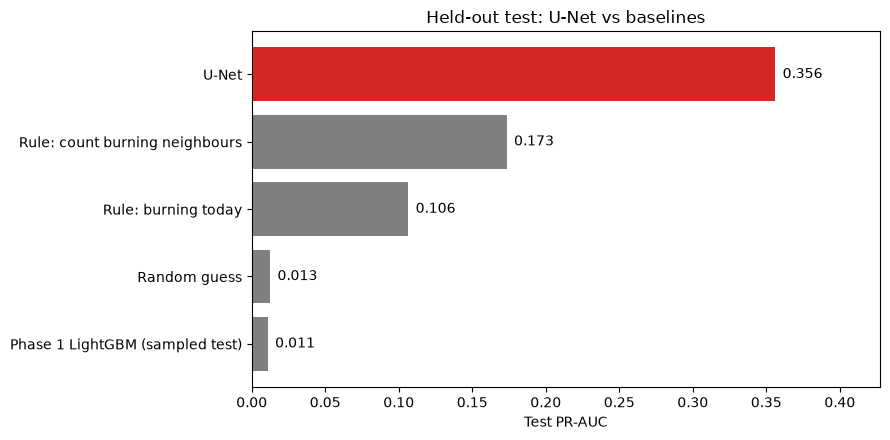

In [5]:
plot_df = results[["model", "test_pr_auc"]].copy()
plot_df.loc[len(plot_df)] = ["Phase 1 LightGBM (sampled test)", phase1["pr_auc"]]
plot_df = plot_df.sort_values("test_pr_auc")

plt.figure(figsize=(9, 4.5))
colors = ["tab:red" if m == "U-Net" else "tab:gray" for m in plot_df["model"]]
bars = plt.barh(plot_df["model"], plot_df["test_pr_auc"], color=colors)
for b, v in zip(bars, plot_df["test_pr_auc"]):
    plt.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
plt.xlabel("Test PR-AUC")
plt.title("Held-out test: U-Net vs baselines")
plt.xlim(0, max(plot_df["test_pr_auc"]) * 1.2)
plt.tight_layout()
plt.savefig("results/figures/dl_test_prauc_comparison.png", dpi=150)
plt.show()


## 5. Precision–recall curves and confusion matrix

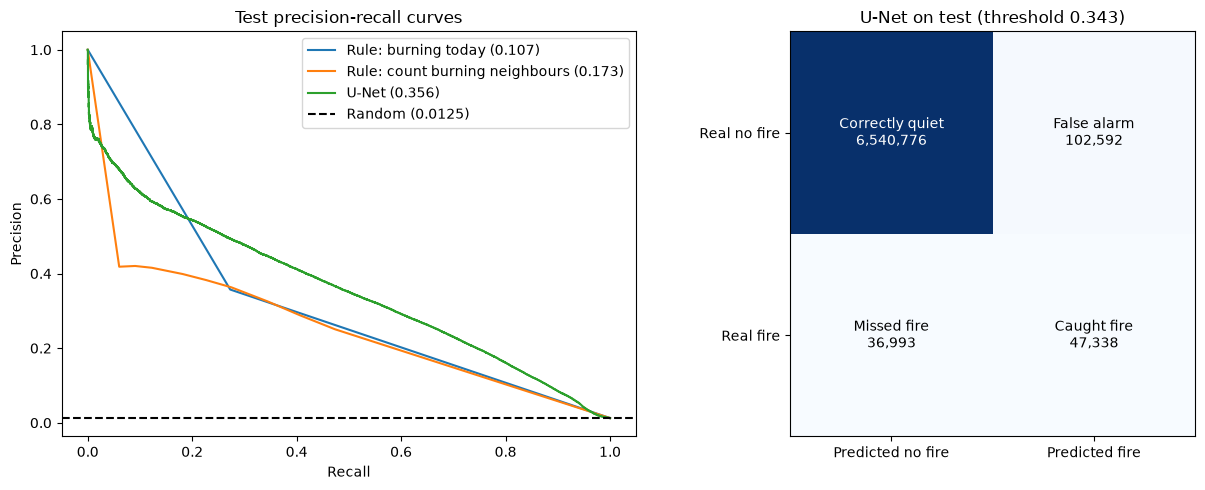

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name in test_scores:
    p, r, _ = precision_recall_curve(y_test, test_scores[name])
    ax[0].plot(r, p, label=f"{name} ({average_precision_score(y_test, test_scores[name]):.3f})")
ax[0].axhline(y_test.mean(), color="black", linestyle="--", label=f"Random ({y_test.mean():.4f})")
ax[0].set_xlabel("Recall")
ax[0].set_ylabel("Precision")
ax[0].set_title("Test precision-recall curves")
ax[0].legend()

cm = np.array([[unet["tn"], unet["fp"]], [unet["fn"], unet["tp"]]])
ax[1].imshow(cm, cmap="Blues")
labels = [["Correctly quiet", "False alarm"], ["Missed fire", "Caught fire"]]
for a in range(2):
    for b in range(2):
        ax[1].text(b, a, f"{labels[a][b]}\n{int(cm[a, b]):,}", ha="center", va="center",
                   color="white" if cm[a, b] > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1], ["Predicted no fire", "Predicted fire"])
ax[1].set_yticks([0, 1], ["Real no fire", "Real fire"])
ax[1].set_title(f"U-Net on test (threshold {unet['threshold']:.3f})")
plt.tight_layout()
plt.savefig("results/figures/dl_test_pr_and_confusion.png", dpi=150)
plt.show()


## 6. Example test maps
We do not hand-pick good maps. Among test maps that have fire tomorrow, we take the ones at the 90th, 50th and 10th percentile of fire size.

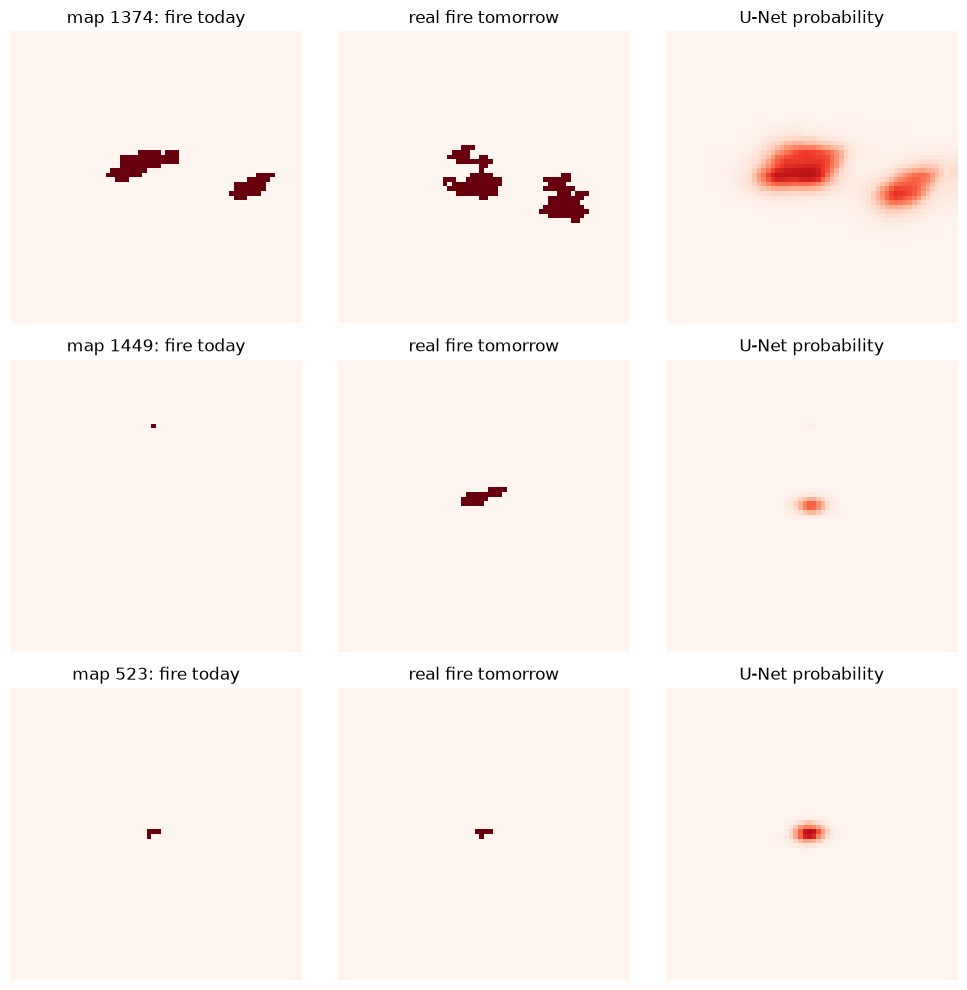

,map,fire_today,fire_tomorrow,predicted_fire,caught
523,523,4,5,15,5
1374,1374,95,145,181,74
1449,1449,1,23,8,2


In [7]:
per_map = []
for k in range(len(test_Y)):
    m = test_Y[k] >= 0
    yk = test_Y[k][m]
    pk = test_prob[k][m]
    predk = pk >= unet["threshold"]
    per_map.append({"map": k, "fire_today": int(test_prev[k].sum()), "fire_tomorrow": int((yk == 1).sum()),
                    "predicted_fire": int(predk.sum()), "caught": int(((yk == 1) & predk).sum())})
per_map = pd.DataFrame(per_map)
per_map.to_csv("results/predictions/dl_test_per_map.csv", index=False)

with_fire = per_map[per_map["fire_tomorrow"] > 0].sort_values("fire_tomorrow").reset_index(drop=True)
picks = [int(with_fire.loc[int(q * (len(with_fire) - 1)), "map"]) for q in [0.9, 0.5, 0.1]]

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
for row, k in enumerate(picks):
    ax[row, 0].imshow(test_prev[k], cmap="Reds", vmin=0, vmax=1)
    ax[row, 0].set_title(f"map {k}: fire today")
    ax[row, 1].imshow(np.where(test_Y[k] < 0, 0.5, test_Y[k]), cmap="Reds", vmin=0, vmax=1)
    ax[row, 1].set_title("real fire tomorrow")
    ax[row, 2].imshow(test_prob[k], cmap="Reds", vmin=0, vmax=1)
    ax[row, 2].set_title("U-Net probability")
    for a in ax[row]:
        a.axis("off")
plt.tight_layout()
plt.savefig("results/figures/dl_test_example_maps.png", dpi=150)
plt.show()
per_map[per_map["map"].isin(picks)]


In [8]:
test_metrics = {"model": "U-Net", "threshold": float(unet["threshold"]),
                "pr_auc": float(unet["test_pr_auc"]), "roc_auc": float(unet["test_roc_auc"]),
                "recall_at_5pct_fpr": float(unet["test_recall_at_5pct_fpr"]),
                "precision": float(unet["test_precision"]), "recall": float(unet["test_recall"]), "f1": float(unet["test_f1"]),
                "confusion_matrix": {"tn": int(unet["tn"]), "fp": int(unet["fp"]), "fn": int(unet["fn"]), "tp": int(unet["tp"])},
                "accuracy": float(accuracy), "always_no_fire_accuracy": float(always_no_fire),
                "test_pixels": int(len(y_test)), "test_fire_rate": float(y_test.mean())}
json.dump(test_metrics, open("results/metrics/dl_test_metrics.json", "w"), indent=2)
test_metrics


{'model': 'U-Net',
 'threshold': 0.3428,
 'pr_auc': 0.3561,
 'roc_auc': 0.9438,
 'recall_at_5pct_fpr': 0.7914,
 'precision': 0.3157,
 'recall': 0.5613,
 'f1': 0.4041,
 'confusion_matrix': {'tn': 6540776, 'fp': 102592, 'fn': 36993, 'tp': 47338},
 'accuracy': 0.9792521930603614,
 'always_no_fire_accuracy': 0.9874651050827333,
 'test_pixels': 6727699,
 'test_fire_rate': 0.012534894917266661}

## 7. Summary
| Model | Test PR-AUC | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|---|
| Random guess | 0.0125 | 0.500 | – | – | – |
| Rule: burning today | 0.107 | 0.633 | 27% | 36% | 0.31 |
| Rule: count burning neighbours | 0.173 | 0.729 | 47% | 25% | 0.33 |
| Phase 1 LightGBM (sampled test) | 0.011 | 0.495 | 0% | 0% | 0.00 |
| **U-Net** | **0.356** | **0.944** | **56%** | **32%** | **0.40** |

- The U-Net is **28 times better than random** on PR-AUC and about **twice the best simple rule**, so it has learned more than "fire stays where it is".
- With the threshold 0.343 chosen on validation it **caught 47,338 of 84,331 fire pixels** and raised 102,592 false alarms among 6.6 million no-fire pixels.
- At 5% false alarms it catches **79%** of fires (Phase 1: 0%).
- Accuracy is still misleading: the U-Net scores 97.93%, while always saying "no fire" scores 98.75%. PR-AUC and F1 are the numbers that matter.
- The example maps show the U-Net finds the right fire areas but gives smooth blobs. It cannot draw the exact ragged edge, which is why precision is about 32%.
- For reference, the dataset paper's convolutional autoencoder reports a test PR-AUC of 0.284 (Huot et al. 2022). Its training setup is not exactly the same as ours, so we call our 0.356 comparable or better, not a direct win.